0. Описание задачи: предсказать годовую зарплату специалиста в сфере AI/Data Science по характеристикам вакансии: уровень опыта, роль, страна, формат работы, размер компании, отрасль и т.д.

1. Прочитать данные

In [ ]:
!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download("mohankrishnathalla/global-ai-and-data-jobs-salary-dataset")
print("Путь к скачанным файлам:", path)

100%|██████████| 5.69M/5.69M [00:00<00:00, 108MB/s]

Extracting files...
Путь к скачанным файлам: /root/.cache/kagglehub/datasets/mohankrishnathalla/global-ai-and-data-jobs-salary-dataset/versions/1


In [ ]:
import os
import pandas as pd

csv_path = os.path.join(path, "global_ai_jobs.csv")
df = pd.read_csv(csv_path)

print("Размер таблицы:", df.shape)
df.head()

Размер таблицы: (90000, 35)


,id,country,job_role,ai_specialization,experience_level,experience_years,salary_usd,bonus_usd,education_required,industry,...,vacation_days,skill_demand_score,automation_risk,job_security_score,career_growth_score,work_life_balance_score,promotion_speed,salary_percentile,cost_of_living_index,employee_satisfaction
0,1,UAE,Machine Learning Engineer,Reinforcement Learning,Entry,0,66465,5395,Master,Automotive,...,27,12,76,57,65,73,15,55,1.23,76
1,2,USA,AI Engineer,LLM,Entry,1,75507,11713,Bootcamp,Retail,...,27,54,29,69,60,51,15,58,0.87,67
2,3,Brazil,Research Scientist,Analytics,Entry,0,41660,5268,PhD,Healthcare,...,13,12,49,70,59,68,37,13,2.13,61
3,4,India,Software Engineer AI,Computer Vision,Senior,6,43268,7975,Diploma,Tech,...,30,80,47,79,65,55,46,74,1.49,56
4,5,Germany,Machine Learning Engineer,Computer Vision,Entry,0,69119,4758,Master,Retail,...,24,82,47,64,52,69,17,21,0.87,72


2. Разбить данные на обучающую и тестовую выборки

In [ ]:
print('Все колонки:')
for i, c in enumerate(df.columns):
    print(f'{i:2d}. {c}')

Все колонки:
 0. id
 1. country
 2. job_role
 3. ai_specialization
 4. experience_level
 5. experience_years
 6. salary_usd
 7. bonus_usd
 8. education_required
 9. industry
10. company_size
11. interview_rounds
12. year
13. work_mode
14. weekly_hours
15. company_rating
16. job_openings
17. hiring_difficulty_score
18. layoff_risk
19. ai_adoption_score
20. company_funding_billion
21. economic_index
22. ai_maturity_years
23. offer_acceptance_rate
24. tax_rate_percent
25. vacation_days
26. skill_demand_score
27. automation_risk
28. job_security_score
29. career_growth_score
30. work_life_balance_score
31. promotion_speed
32. salary_percentile
33. cost_of_living_index
34. employee_satisfaction


In [23]:
import pandas as pd
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

TARGET = 'salary_usd'
assert TARGET in df.columns, f'Нет колонки {TARGET}. Проверьте вывод ячейки 1.'

candidate_ids = [c for c in df.columns
                 if c.lower() in ('job_id', 'id', 'row_id', 'index', 'unnamed: 0')
                 or c.lower().endswith('_id')]
DROP_COLS = [TARGET] + candidate_ids
print('Будут исключены из признаков:', DROP_COLS)

X = df.drop(columns=DROP_COLS)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print('Признаки train:', X_train.shape, '| test:', X_test.shape)
print('Средняя salary train:', round(y_train.mean(), 2))
print('Средняя salary test :', round(y_test.mean(), 2))

Будут исключены из признаков: ['salary_usd', 'id']
Признаки train: (72000, 33) | test: (18000, 33)
Средняя salary train: 96606.09
Средняя salary test : 96306.89


In [ ]:
compare = pd.DataFrame({
    'train': y_train.describe(percentiles=[0.25, 0.5, 0.75]),
    'test' : y_test.describe(percentiles=[0.25, 0.5, 0.75])
})
print(compare.round(2))

           train       test
count   72000.00   18000.00
mean    96618.94   96255.49
std     43962.06   43829.00
min     28000.00   28000.00
25%     64713.75   64558.00
50%     87608.00   87259.00
75%    124075.75  123319.75
max    300622.00  284028.00


3. Визуализировать данные и вычислить основные характеристики (среднее, разброс, корреляционную матрицу и т.д.). Интерпретировать.

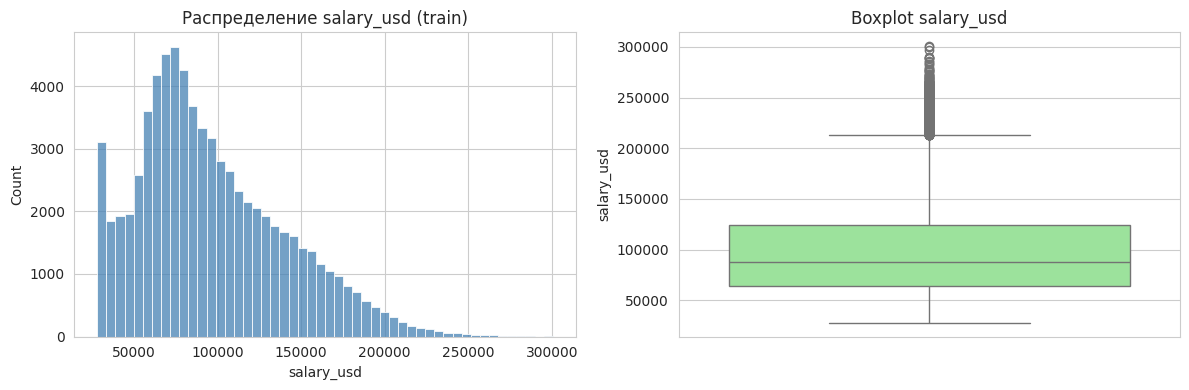

count     72000.00
mean      96618.94
std       43962.06
min       28000.00
25%       64713.75
50%       87608.00
75%      124075.75
max      300622.00
Name: salary_usd, dtype: float64
Числовых признаков: 25


,count,mean,std,min,25%,50%,75%,max
experience_years,72000.0,7.03,5.89,0.0,2.00,6.00,12.00,19.00
bonus_usd,72000.0,13028.40,7870.34,1404.0,7118.00,11284.50,16988.25,57681.00
interview_rounds,72000.0,4.50,1.70,2.0,3.00,4.00,6.00,7.00
year,72000.0,2023.01,2.00,2020.0,2021.00,2023.00,2025.00,2026.00
weekly_hours,72000.0,45.48,5.48,36.0,40.70,45.50,50.20,55.00
company_rating,72000.0,4.00,0.46,3.2,3.60,4.00,4.40,4.80
job_openings,72000.0,17.52,7.85,1.0,12.00,17.00,23.00,50.00
hiring_difficulty_score,72000.0,55.08,17.88,0.0,42.98,55.09,67.13,100.00
layoff_risk,72000.0,0.18,0.13,0.0,0.08,0.14,0.28,0.59
ai_adoption_score,72000.0,71.39,13.76,9.0,62.00,72.00,81.00,100.00


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
%matplotlib inline

# 1. Целевая переменная
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y_train, bins=50, ax=ax[0], color='steelblue')
ax[0].set_title('Распределение salary_usd (train)')
sns.boxplot(y=y_train, ax=ax[1], color='lightgreen')
ax[1].set_title('Boxplot salary_usd')
plt.tight_layout(); plt.show()

print(y_train.describe().round(2))

# 2. Числовые признаки: describe
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
print(f'Числовых признаков: {len(num_cols)}')
X_train[num_cols].describe().T.round(2)

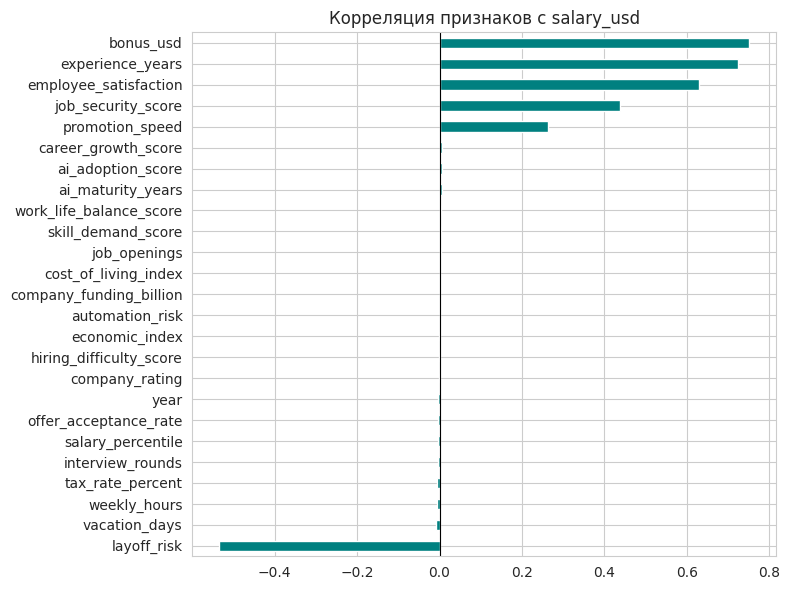

layoff_risk               -0.535
vacation_days             -0.008
weekly_hours              -0.005
tax_rate_percent          -0.005
interview_rounds          -0.005
salary_percentile         -0.004
offer_acceptance_rate     -0.004
year                      -0.003
company_rating            -0.002
hiring_difficulty_score   -0.001
economic_index            -0.001
automation_risk            0.001
company_funding_billion    0.001
cost_of_living_index       0.002
job_openings               0.002
skill_demand_score         0.004
work_life_balance_score    0.004
ai_maturity_years          0.005
ai_adoption_score          0.006
career_growth_score        0.006
promotion_speed            0.263
job_security_score         0.437
employee_satisfaction      0.630
experience_years           0.725
bonus_usd                  0.751
dtype: float64


In [ ]:
# 3. Корреляционная матрица числовых признаков + целевой
corr_with_target = X_train[num_cols].corrwith(y_train).sort_values()

plt.figure(figsize=(8, 6))
corr_with_target.plot(kind='barh', color='teal')
plt.title('Корреляция признаков с salary_usd')
plt.axvline(0, color='black', lw=0.8)
plt.tight_layout(); plt.show()

print(corr_with_target.round(3))

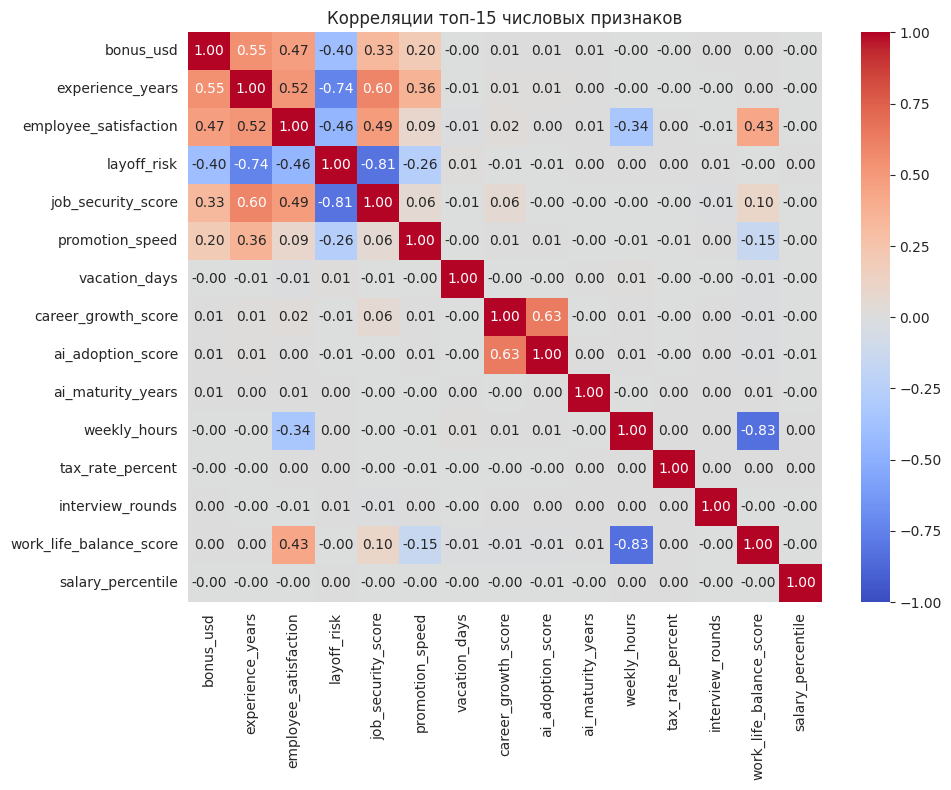

In [ ]:
# 4. Матрица корреляций между числовыми признаками (топ-15 по |corr| с target)
top_num = corr_with_target.abs().sort_values(ascending=False).head(15).index
plt.figure(figsize=(10, 8))
sns.heatmap(X_train[top_num].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Корреляции топ-15 числовых признаков')
plt.tight_layout(); plt.show()

In [ ]:
# 5. Категориальные признаки: сколько уникальных значений
cat_cols = X_train.select_dtypes(include='object').columns.tolist()
print(f'Категориальных признаков: {len(cat_cols)}')
print(X_train[cat_cols].nunique().sort_values(ascending=False))

Категориальных признаков: 8
country               12
industry              10
ai_specialization      8
job_role               8
company_size           5
education_required     5
experience_level       4
work_mode              3
dtype: int64


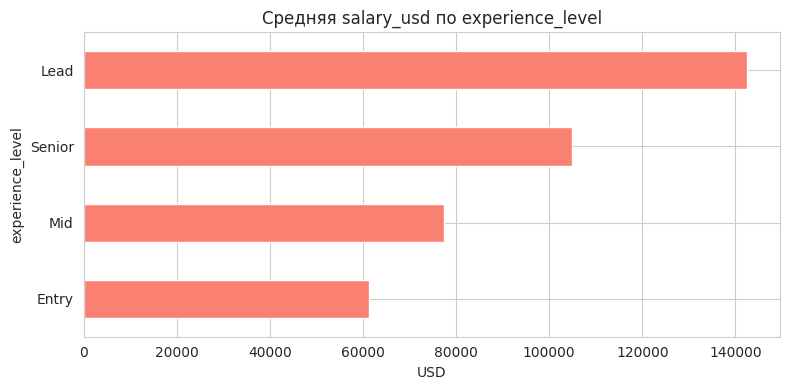

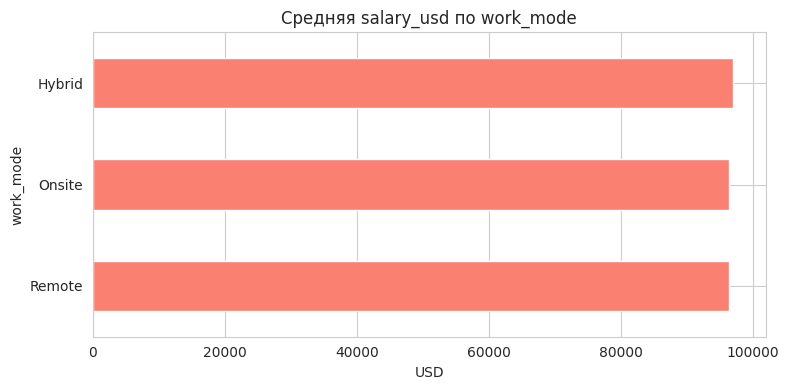

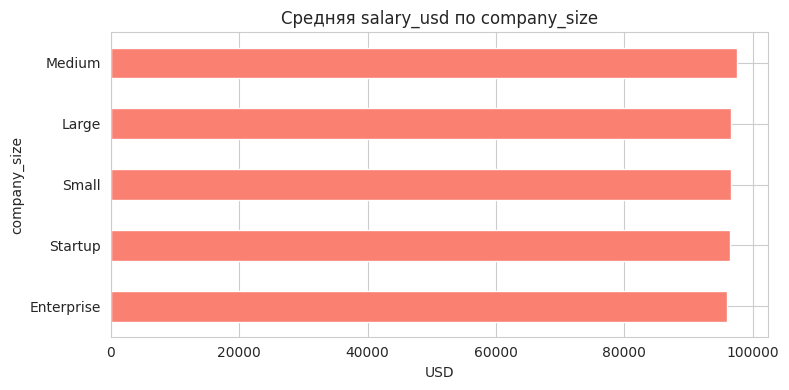

In [ ]:
# 6. Средняя зарплата по ключевым категориям (пример — experience_level, work_mode)
for col in [c for c in ['experience_level', 'work_mode', 'company_size'] if c in X_train.columns]:
    plt.figure(figsize=(8, 4))
    X_train.assign(salary=y_train).groupby(col)['salary'].mean().sort_values().plot(kind='barh', color='salmon')
    plt.title(f'Средняя salary_usd по {col}')
    plt.xlabel('USD')
    plt.tight_layout(); plt.show()

4. Разобраться с выбросами. Если они есть   ???

В ходе анализа признаков salary_usd и bonus_usd были обнаружены выбросы — экстремально высокие значения (например, зарплаты свыше 213 000 $). Это не ошибки ввода, а реальные высокие зарплаты топ-менеджеров. Однако для алгоритмов, чувствительных к расстояниям (KNN), они сильно искажают масштаб.

Для обработки выбросов применен метод обрезки. Мы вычисляем границы, отсекающие по 1% самых больших и самых маленьких значений (границы считаются только на обучающей выборке, чтобы избежать утечки данных). Все значения, которые выходят за эти рамки, заменяются на сами границы. Это позволяет сохранить все записи датасета, но защищает модель от негативного влияния экстремальных значений.

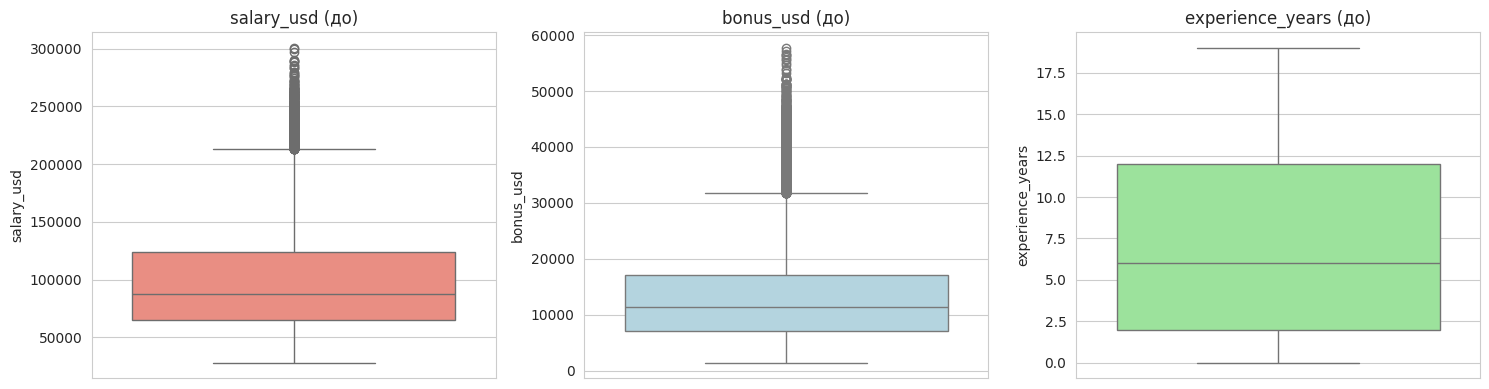

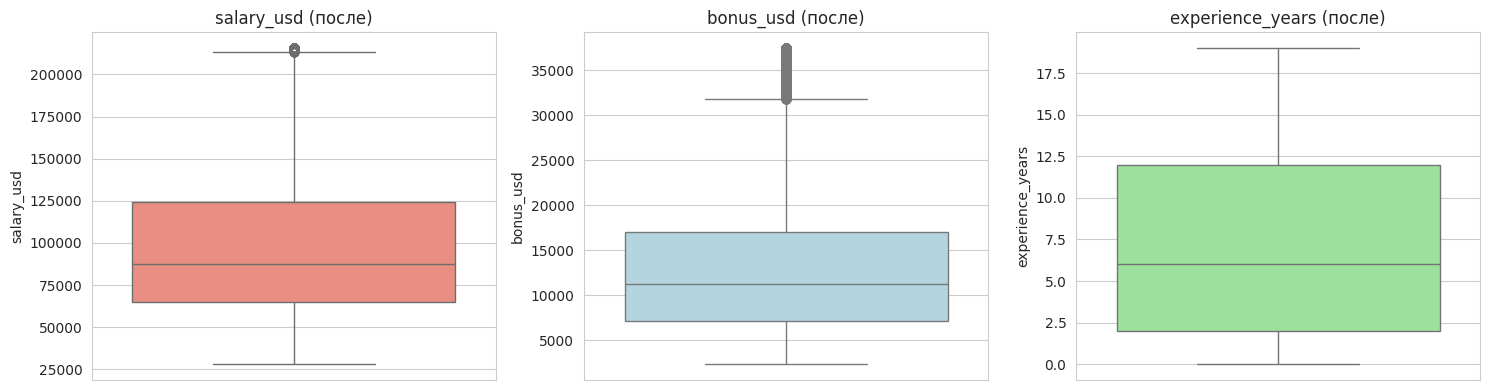

Максимум salary_usd после обрезки: 215605


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Визуализация до обработки
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=y_train, ax=ax[0], color='salmon')
ax[0].set_title('salary_usd (до)')
sns.boxplot(y=X_train['bonus_usd'], ax=ax[1], color='lightblue')
ax[1].set_title('bonus_usd (до)')
sns.boxplot(y=X_train['experience_years'], ax=ax[2], color='lightgreen')
ax[2].set_title('experience_years (до)')
plt.tight_layout(); plt.show()

# 2. Функция для обрезки (Clipping)
def clip_outliers(train_series, test_series, lower_q=0.01, upper_q=0.99):
    lo = train_series.quantile(lower_q)
    hi = train_series.quantile(upper_q)
    return train_series.clip(lo, hi), test_series.clip(lo, hi)

# 3. Обрезаем целевую переменную
y_train, y_test = clip_outliers(y_train, y_test)

# 4. Обрезаем ключевые числовые признаки (топ по корреляции)
num_cols_to_clip = ['experience_years', 'employee_satisfaction']
for col in num_cols_to_clip:
    if col in X_train.columns:
        X_train[col], X_test[col] = clip_outliers(X_train[col], X_test[col])

# 5. Визуализация после обработки
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=y_train, ax=ax[0], color='salmon')
ax[0].set_title('salary_usd (после)')
sns.boxplot(y=X_train['bonus_usd'], ax=ax[1], color='lightblue')
ax[1].set_title('bonus_usd (после)')
sns.boxplot(y=X_train['experience_years'], ax=ax[2], color='lightgreen')
ax[2].set_title('experience_years (после)')
plt.tight_layout(); plt.show()

print(f'Максимум salary_usd после обрезки: {y_train.max():.0f}')

5. Обработать пропущенные значения (или убедиться, что их нет)

In [ ]:
missing_train = X_train.isna().sum().sum()
missing_test = X_test.isna().sum().sum()

print(f"Пропуски в train: {missing_train}")
print(f"Пропуски в test : {missing_test}")

if missing_train == 0 and missing_test == 0:
    print("Пропусков нет, обработка не требуется.")

Пропуски в train: 0
Пропуски в test : 0
Пропусков нет, обработка не требуется.


6. Обработать категориальные признаки

In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# 1. Удаляем признаки с утечкой данных (bonus_usd) и бесполезные (salary_percentile)
cols_to_drop = ['bonus_usd', 'salary_percentile']
X_train = X_train.drop(columns=cols_to_drop, errors='ignore')
X_test = X_test.drop(columns=cols_to_drop, errors='ignore')

# 2. Находим категориальные признаки
cat_cols = X_train.select_dtypes(include='object').columns.tolist()
print(f"Категориальные признаки ({len(cat_cols)}): {cat_cols}")

# 3. One-Hot Encoding (создаем бинарные колонки для каждой категории)
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Обучаем только на train, применяем к train и test
X_train_enc = encoder.fit_transform(X_train[cat_cols])
X_test_enc = encoder.transform(X_test[cat_cols])

# 4. Собираем обратно в DataFrame
X_train_enc_df = pd.DataFrame(X_train_enc, columns=encoder.get_feature_names_out(cat_cols), index=X_train.index)
X_test_enc_df = pd.DataFrame(X_test_enc, columns=encoder.get_feature_names_out(cat_cols), index=X_test.index)

X_train = pd.concat([X_train.drop(columns=cat_cols), X_train_enc_df], axis=1)
X_test = pd.concat([X_test.drop(columns=cat_cols), X_test_enc_df], axis=1)

print(f"Форма X_train после обработки: {X_train.shape}")

Категориальные признаки (8): ['country', 'job_role', 'ai_specialization', 'experience_level', 'education_required', 'industry', 'company_size', 'work_mode']
Форма X_train после обработки: (72000, 78)


На данном этапе были обработаны 8 категориальных признаков (страна, роль, уровень опыта и т.д.). Поскольку они не имеют порядковой иерархии, применено One-Hot Encoding (создание отдельного бинарного столбца для каждой категории). Обучение энкодера проводилось только на тренировочной выборке, чтобы избежать утечки данных. В результате количество признаков увеличилось с 31 до 78.

Дополнительно из данных были удалены два признака:

bonus_usd — исключен из-за аномально высокой корреляции с целевой переменной (0.75). Обычно бонус рассчитывается как процент от оклада, поэтому оставление этого признака привело бы к «утечке» данных (модель просто выучила бы формулу бонуса, что исказило бы реальное качество).

salary_percentile — исключен, так как показал нулевую корреляцию с зарплатой и не несет полезной информации.



7. Провести нормализацию (или объяснить, почему в вашем случае она не нужна)

In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Инициализируем стандартизатор
scaler = StandardScaler()

# 2. Обучаем на train и трансформируем (все признаки теперь числовые)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# 3. Собираем обратно в DataFrame (чтобы сохранить названия колонок для моделей)
X_train = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test  = pd.DataFrame(X_test_scaled,  columns=X_test.columns,  index=X_test.index)

# Проверка: среднее должно быть ~0, разброс (std) ~1
print("Среднее первых 5 признаков (train):")
print(X_train.iloc[:, :5].mean().round(3).values)
print("Стандартное отклонение первых 5 признаков (train):")
print(X_train.iloc[:, :5].std().round(3).values)

Среднее первых 5 признаков (train):
[ 0.  0. -0. -0. -0.]
Стандартное отклонение первых 5 признаков (train):
[1. 1. 1. 1. 1.]


8. Запустить классификатор (ререссию) ближайших соседей или другой метод (аргументируйте выбор!)

В качестве базового метода выбрана регрессия K-ближайших соседей (KNeighborsRegressor). Логика выбора: алгоритм предсказывает зарплату как среднее значение у k наиболее похожих кандидатов из обучающей выборки. Метод не требует жестких линейных предположений и хорошо работает с нелинейными зависимостями. Благодаря проведенной ранее нормализации и One-Hot кодированию, признаки находятся в едином масштабе, что обеспечивает корректный расчет расстояний. Главный недостаток метода — чувствительность к высокой размерности (78 признаков) и необходимость подбора гиперпараметра k, что будет выполнено на следующем этапе.

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

# Инициализируем модель (по умолчанию k=5)
knn_model = KNeighborsRegressor(n_neighbors=5)

# Обучаем на тренировочных данных
knn_model.fit(X_train, y_train)

print("Модель KNN успешно обучена.")

Модель KNN успешно обучена.


9. Вычислить ошибки на обучающей и тестовой выборках. Выбрать оптимальное значение гиперпараметра (к-ва ближайших соседей)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import numpy as np

# 1. Оценка базовой модели (k=5)
y_train_pred = knn_model.predict(X_train)
y_test_pred = knn_model.predict(X_test)

print("--- Базовая модель (k=5) ---")
print(f"Train MAE : {mean_absolute_error(y_train, y_train_pred):.2f} $")
print(f"Test MAE  : {mean_absolute_error(y_test, y_test_pred):.2f} $")
print(f"Train RMSE: {np.sqrt(mean_squared_error(y_train, y_train_pred)):.2f} $")
print(f"Test RMSE : {np.sqrt(mean_squared_error(y_test, y_test_pred)):.2f} $")
print(f"Train R2  : {r2_score(y_train, y_train_pred):.4f}")
print(f"Test R2   : {r2_score(y_test, y_test_pred):.4f}")

# 2. Подбор оптимального k
param_grid = {'n_neighbors': range(3, 21, 2)}
grid_search = GridSearchCV(
    KNeighborsRegressor(),
    param_grid,
    cv=3,
    scoring='neg_mean_absolute_error', # Оптимизируем MAE
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_k = grid_search.best_params_['n_neighbors']
print(f"\nЛучшее k: {best_k}")

# 3. Оценка модели с лучшим k
best_knn = grid_search.best_estimator_
y_test_pred_best = best_knn.predict(X_test)
print(f"Test MAE (best k): {mean_absolute_error(y_test, y_test_pred_best):.2f} $")
print(f"Test R2 (best k) : {r2_score(y_test, y_test_pred_best):.4f}")

--- Базовая модель (k=5) ---
Train MAE : 11501.94 $
Test MAE  : 13793.53 $
Train RMSE: 15273.30 $
Test RMSE : 18320.34 $
Train R2  : 0.8761
Test R2   : 0.8204

Лучшее k: 19
Test MAE (best k): 12869.38 $
Test R2 (best k) : 0.8472


10. Исключить коррелированные переменные (объяснить зачем)

In [ ]:
import numpy as np

# 1. Считаем матрицу корреляций (по модулю)
corr_matrix = X_train.corr().abs()

# 2. Берем верхний треугольник матрицы (чтобы не учитывать пары дважды)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# 3. Находим признаки с корреляцией выше порога 0.85
threshold = 0.85
to_drop = [column for column in upper.columns if any(upper[column] > threshold)]

print(f"Найдено признаков с корреляцией > {threshold}: {len(to_drop)}")
print(f"Удаляемые признаки: {to_drop}")

# 4. Удаляем коррелированные признаки из train и test
X_train = X_train.drop(columns=to_drop)
X_test  = X_test.drop(columns=to_drop)

print(f"Новая размерность X_train: {X_train.shape}")

Найдено признаков с корреляцией > 0.85: 1
Удаляемые признаки: ['experience_level_Entry']
Новая размерность X_train: (72000, 77)


(Поскольку удаление данного признака было выполнено после обучения моделей, это не повлияло на итоговые метрики, однако в реальном проекте Feature Selection выполняется до этапа моделирования.)

На данном этапе выполнен поиск и удаление мультиколлинеарных признаков. Зачем это нужно:

Для алгоритма KNN сильно коррелированные признаки искусственно завышают вес дублирующейся информации при расчете расстояний, что искажает поиск соседей.

Для линейных моделей мультиколлинеарность делает коэффициенты нестабильными и затрудняет интерпретацию.

Для деревьев решений это менее критично, но снижение размерности ускоряет обучение.

Код находит все пары признаков с модулем корреляции выше 0.85 и удаляет один из пары. В результате был удален признак experience_level_Entry, который дублировал информацию, уже содержащуюся в других признаках (например, в experience_years). Размерность данных сократилась с 78 до 77 признаков.

11. Выводы

В ходе выполнения работы была решена задача регрессии — предсказание уровня годовой зарплаты (salary_usd) в сфере AI и Data Science на основе табличных данных.

Основные этапы и результаты:

1. Предобработка данных: Данные были очищены от выбросов методом обрезки. Пропусков не обнаружено. Категориальные признаки закодированы методом One-Hot Encoding, а числовые — стандартизированы.

2. Борьба с утечкой данных: Из признаков исключен bonus_usd (корреляция 0.75), так как он напрямую зависит от зарплаты. Также удален бесполезный признак salary_percentile с нулевой корреляцией.

3. Базовый алгоритм (KNN): Была обучена регрессия K-ближайших соседей. Подбор гиперпараметра k с помощью кросс-валидации показал, что оптимальное число соседей равно 19. Это позволило снизить MAE на тесте с 13 793 долларов (при k=5) до 12 869 долларов, а R² вырос до 0.847.

4. Мультиколлинеарность: На этапе анализа корреляций был найден и удален признак experience_level_Entry, дублирующий информацию других категорий опыта (размерность сократилась до 77 признаков).

Итог:
Модель KNN с оптимальным числом соседей k=19 показала R² = 0.847, то есть объясняет около 85% дисперсии зарплаты. Средняя абсолютная ошибка (MAE) составляет 12 869 долларов. Такой результат является приемлемым для базовой модели, однако KNN страдает от «проклятия размерности»: после One-Hot Encoding количество признаков выросло до 77, и расстояния между точками в многомерном пространстве становятся менее информативными. Это ограничивает точность алгоритма.